<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

توزيع الرسائل:
label
ham     4825
spam     747
Name: count, dtype: int64


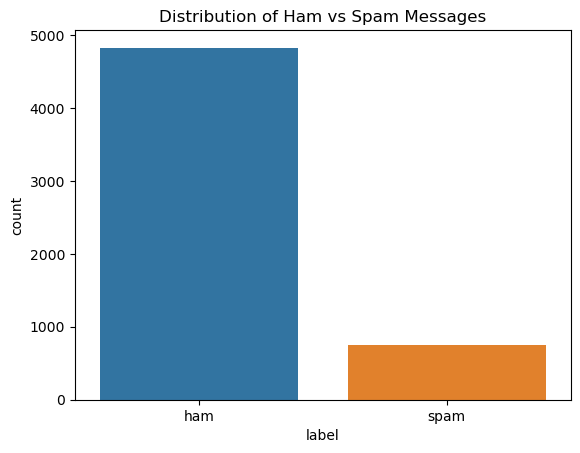

In [1]:
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# تحميل ملف البيانات المعتمد من مستودع UCI مباشرة
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
urllib.request.urlretrieve(url, "sms.zip")

# فك ضغط الملف
with zipfile.ZipFile("sms.zip", "r") as zip_ref:
  zip_ref.extractall("sms_data")

# قراءة البيانات في DataFrame
df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
)

# طباعة عدد وأول 5 رسائل
print(df.info())
print("\nتوزيع الرسائل:")
print(df["label"].value_counts())

# رسم بياني لتوزيع الرسائل (Ham vs Spam)
sns.countplot(x=df["label"])
plt.title("Distribution of Ham vs Spam Messages")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\aasf2\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\aasf2\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


================== عينة قبل وبعد التنظيف ==================
النص الأصلي (قبل):
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

النص بعد المعالجة (بعد):
go jurong point crazi avail bugi n great world la e buffet cine got amor wat


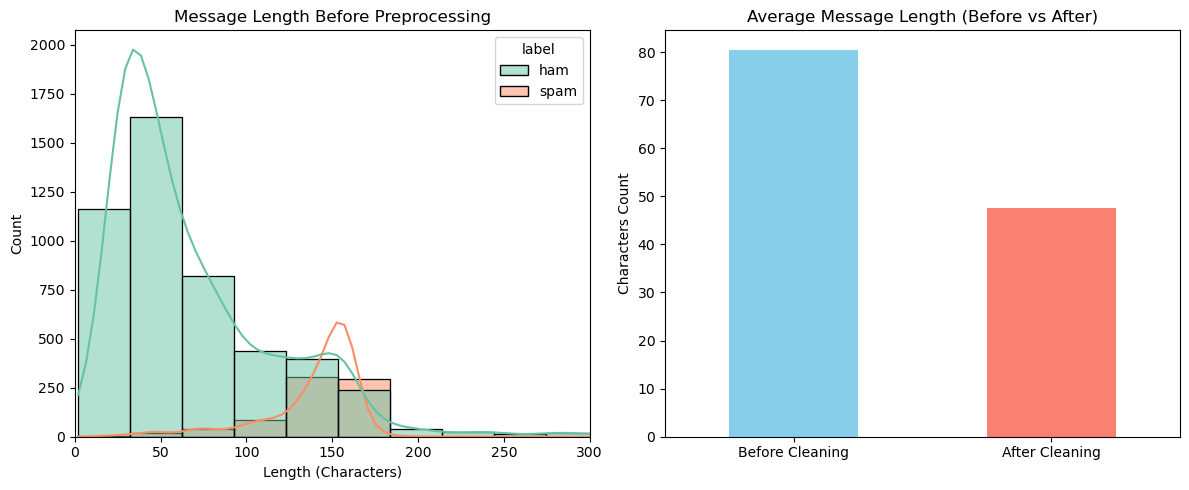

In [3]:
import re
import string
import matplotlib.pyplot as plt
import nltk
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# تحميل قائمة الكلمات التوقفية وحزمة التقطيع
nltk.download("stopwords")
nltk.download("punkt")

stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))


# مسار تنظيف النصوص المعتمد للمشروع
def preprocess_text(text):
  text = text.lower()  # 1. توحيد حالة الأحرف
  text = re.sub(r"\d+", "", text)  # 2. إزالة الأرقام
  text = text.translate(
      str.maketrans("", "", string.punctuation)
  )  # 3. إزالة علامات الترقيم
  tokens = text.split()  # 4. تقطيع النص
  # 5. حذف الكلمات التوقفية وتجذير الكلمات
  cleaned_tokens = [
      stemmer.stem(word) for word in tokens if word not in stop_words
  ]
  return " ".join(cleaned_tokens)


# تطبيق مسار التنظيف
df["cleaned_message"] = df["message"].apply(preprocess_text)

# حساب طول الرسالة (عدد الأحرف) قبل وبعد التنظيف للمقارنة
df["length_before"] = df["message"].apply(len)
df["length_after"] = df["cleaned_message"].apply(len)

# -------------------------------------------------------------
# المخرجات 1: طباعة أمثلة نصية (مطلوبة حرفياً في Task 1 بالتقرير)
# -------------------------------------------------------------
print("================== عينة قبل وبعد التنظيف ==================")
print("النص الأصلي (قبل):")
print(df["message"].iloc[0])
print("\nالنص بعد المعالجة (بعد):")
print(df["cleaned_message"].iloc[0])
print("=" * 60)

# -------------------------------------------------------------
# المخرجات 2: الرسم البياني المطلوب للمقارنة
# -------------------------------------------------------------
plt.figure(figsize=(12, 5))

# الرسم الأول: مقارنة توزيع أطوال الرسائل للرسائل العادية والمزعجة
plt.subplot(1, 2, 1)
sns.histplot(
    data=df,
    x="length_before",
    hue="label",
    bins=30,
    kde=True,
    palette="Set2",
)
plt.title("Message Length Before Preprocessing")
plt.xlabel("Length (Characters)")
plt.xlim(0, 300)

# الرسم الثاني: متوسط طول النصوص قبل وبعد المعالجة
plt.subplot(1, 2, 2)
df[["length_before", "length_after"]].mean().plot(kind="bar", color=["skyblue", "salmon"])
plt.title("Average Message Length (Before vs After)")
plt.ylabel("Characters Count")
plt.xticks(ticks=[0, 1], labels=["Before Cleaning", "After Cleaning"], rotation=0)

plt.tight_layout()
plt.show()